# 23CSE301 Machine Learning — Capstone Project
## Track 3: Clustering — **K-Means** (Review 2)
### Dataset: *FinRisk* — Credit Risk Dataset (Borrower Segmentation)

**Problem statement.** Group loan applicants into **natural borrower segments** based on their
demographics, income, loan characteristics and credit history — *without using any label while
fitting*. The dataset does contain a `loan_status` column (1 = defaulted), but per the guidelines
(§3.3) ground-truth labels may only be used **after** the fact, to interpret or validate the
clusters. We therefore keep `loan_status` out of the feature matrix entirely and use it only in §12.

**Scope of this notebook.** K-Means clustering (algorithm 1 of 2 in the clustering track).
Agglomerative Hierarchical Clustering (algorithm 2) is in a sibling notebook owned by another team
member and runs on **the same preprocessed data** that §6 and §13 of this notebook export to disk.

**Mandatory evaluation metrics:** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index.
**Mandatory visuals:** Elbow curve (inertia vs. k), PCA 2-D cluster plot. **Encouraged:** t-SNE.

---

### How this notebook maps to the Review 2 rubric (Clustering, Section B)

| Rubric item | Marks | Where it is addressed |
|---|---|---|
| B1 Implementation — algorithm fitted, labels obtained, no errors | 4 (shared with sibling notebook) | §8 |
| B2 Metrics — Silhouette, Davies-Bouldin, Calinski-Harabasz; Elbow curve | 2 (shared) | §7 (Elbow + sweep), §8 (final metrics) |
| B3 Visualisation — PCA 2-D with cluster colours; t-SNE for at least one algorithm | 2 (shared) | §9 (PCA), §10 (t-SNE) |
| C1 Code quality — runs top-to-bottom, modular functions, commented | 1 (shared) | Whole notebook; reusable functions defined in §1 and §8 |

> **Coordination note.** Clustering has no train/test split, but the two algorithms must still be
> compared on **identical data**. §13 exports the cleaned + scaled feature matrix *and* a fixed
> 8,000-row shared sample (agglomerative clustering is memory-hungry on tens of thousands of rows), so both
> notebooks can be scored on exactly the same rows.

---
## 1. Setup and reproducibility

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
import joblib

RANDOM_STATE = 42
SAMPLE_N     = 8000        # shared sample size for the K-Means vs. Agglomerative comparison
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)


def cluster_metrics(X, labels, sample_size=None, seed=RANDOM_STATE):
    # Returns the three mandatory internal clustering metrics.
    # silhouette is O(n^2); sample_size lets us subsample for speed when needed.
    X = np.asarray(X)
    labels = np.asarray(labels)
    if sample_size is not None and sample_size < len(X):
        idx = np.random.RandomState(seed).choice(len(X), sample_size, replace=False)
        sil = silhouette_score(X[idx], labels[idx])
    else:
        sil = silhouette_score(X, labels)
    return {
        "Silhouette":         sil,
        "Davies-Bouldin":     davies_bouldin_score(X, labels),
        "Calinski-Harabasz":  calinski_harabasz_score(X, labels),
    }

print("Environment ready. pandas", pd.__version__, "| numpy", np.__version__)

Environment ready. pandas 3.0.2 | numpy 2.4.4


---
## 2. Data loading and audit

Download link: <https://www.kaggle.com/datasets/laotse/credit-risk-dataset>
Place `credit_risk_dataset.csv` at `data/credit_risk_dataset.csv`.

| Column | Meaning | Type |
|---|---|---|
| `person_age` | Applicant age (years) | numeric |
| `person_income` | Annual income | numeric |
| `person_home_ownership` | RENT / OWN / MORTGAGE / OTHER | nominal |
| `person_emp_length` | Years employed | numeric |
| `loan_intent` | Purpose of loan (6 categories) | nominal |
| `loan_grade` | Lender's risk grade A (best) – G (worst) | **ordinal** |
| `loan_amnt` | Loan amount | numeric |
| `loan_int_rate` | Interest rate (%) | numeric |
| `loan_status` | 1 = defaulted, 0 = repaid | **label — NOT used for fitting** |
| `loan_percent_income` | loan_amnt / income | numeric |
| `cb_person_default_on_file` | Previous default on credit-bureau file (Y/N) | binary |
| `cb_person_cred_hist_length` | Length of credit history (years) | numeric |

In [2]:
CANDIDATE_PATHS = [
    "../data/credit_risk_dataset.csv",
    "data/credit_risk_dataset.csv",
    "credit_risk_dataset.csv",
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("credit_risk_dataset.csv not found. Download it from Kaggle and place it in data/.")

df_raw = pd.read_csv(DATA_PATH)

EXPECTED = ["person_age", "person_income", "person_home_ownership", "person_emp_length",
            "loan_intent", "loan_grade", "loan_amnt", "loan_int_rate", "loan_status",
            "loan_percent_income", "cb_person_default_on_file", "cb_person_cred_hist_length"]
missing_cols = [c for c in EXPECTED if c not in df_raw.columns]
assert not missing_cols, f"Unexpected schema - missing columns: {missing_cols}"

print("Loaded from:", DATA_PATH)
print("Raw shape  :", df_raw.shape)
df_raw.head()

Loaded from: ../data/credit_risk_dataset.csv
Raw shape  : (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
audit = pd.DataFrame({
    "dtype":     df_raw.dtypes.astype(str),
    "missing":   df_raw.isnull().sum(),
    "missing_%": (df_raw.isnull().mean() * 100).round(2),
    "n_unique":  df_raw.nunique(),
    "example":   df_raw.iloc[0],
})
display(audit)

print("\nExact duplicate rows:", df_raw.duplicated().sum())
display(df_raw.describe().T.round(2))

,dtype,missing,missing_%,n_unique,example
person_age,int64,0,0.00,58,22
person_income,int64,0,0.00,4295,59000
person_home_ownership,str,0,0.00,4,RENT
person_emp_length,float64,895,2.75,36,123.0
loan_intent,str,0,0.00,6,PERSONAL
loan_grade,str,0,0.00,7,D
loan_amnt,int64,0,0.00,753,35000
loan_int_rate,float64,3116,9.56,348,16.02
loan_status,int64,0,0.00,2,1
loan_percent_income,float64,0,0.00,77,0.59



Exact duplicate rows: 165


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.85,61983.12,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.37,6322.09,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.80,4.06,2.00,3.00,4.00,8.00,30.00


> ### Observation — dataset audit
>
> * **Two columns have missing values** — `person_emp_length` and `loan_int_rate`. Missing
>   interest rates are by far the larger problem, so the imputation choice (§4) matters.
> * **`describe()` exposes impossible values that `isnull()` cannot see.** This dataset is known to
>   contain ages well above 100 and employment lengths far above any human working life — the `max`
>   column above will show them. These are data-entry errors, i.e. *disguised missing data*.
> * **Income is extremely right-skewed** — the maximum is many times the 75th percentile. Because
>   K-Means measures raw Euclidean distance, a few multi-million incomes would otherwise dominate the
>   distance calculation and drag centroids toward themselves. We handle this with a log transform (§5).
> * **Duplicate rows exist** and are removed in §4.
> * **`loan_status` is present, but it is a label.** Using it as a clustering input would make the
>   segmentation partly a *restatement of the answer*; the guidelines forbid using labels during
>   fitting, so it is excluded from every step up to §12.

---
## 3. Exploratory Data Analysis

For clustering, EDA has a specific purpose: **does the data show natural groupings, and which
features are on wildly different scales or heavily skewed?** Both questions decide how we
preprocess, because K-Means is distance-based and assumes roughly spherical, similar-sized groups.

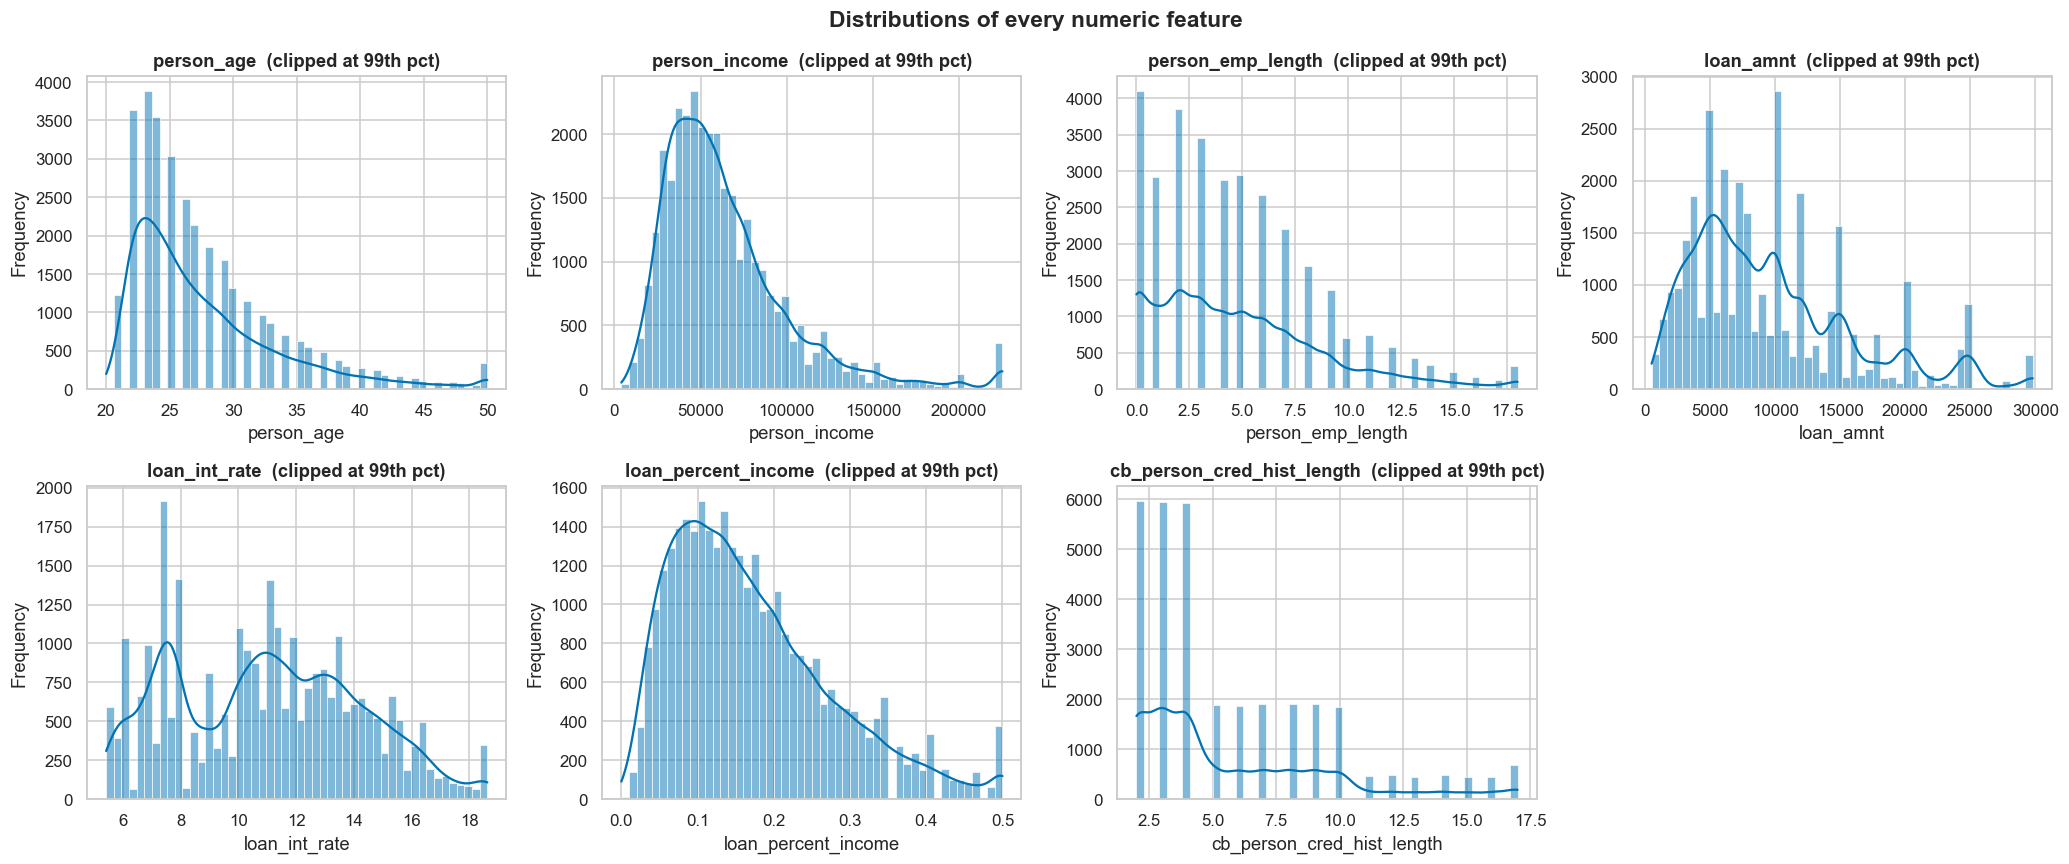

Skewness (raw):


,skew
person_age,2.58
person_income,32.87
person_emp_length,2.61
loan_amnt,1.19
loan_int_rate,0.21
loan_percent_income,1.06
cb_person_cred_hist_length,1.66


In [4]:
numeric_eda = ["person_age", "person_income", "person_emp_length", "loan_amnt",
               "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]

fig, axes = plt.subplots(2, 4, figsize=(19, 8))
axes = axes.ravel()
for ax, col in zip(axes, numeric_eda):
    s = df_raw[col].dropna()
    s = s.clip(upper=s.quantile(0.99))          # clip ONLY for display; raw data unchanged
    sns.histplot(s, bins=50, kde=True, ax=ax, color="#0173b2")
    ax.set_title(f"{col}  (clipped at 99th pct)")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
axes[-1].set_visible(False)
fig.suptitle("Distributions of every numeric feature", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

print("Skewness (raw):")
display(df_raw[numeric_eda].skew().round(2).to_frame("skew"))

> ### Observation — numeric distributions
>
> * **Income and loan amount are strongly right-skewed** (large positive skewness in the table
>   above), while age and credit-history length are right-skewed but milder. Heavily skewed features
>   would make K-Means carve clusters mostly along the income axis, because a handful of very large
>   values stretch that dimension — so we log-transform income and loan amount in §5.
> * **The features live on completely different scales** — age in tens, income in tens of thousands.
>   Without standardisation, income alone would decide almost every distance. Scaling is mandatory.
> * **`loan_percent_income` and `loan_int_rate` look closer to bell-shaped**, so they are better
>   behaved inputs for a distance-based method.

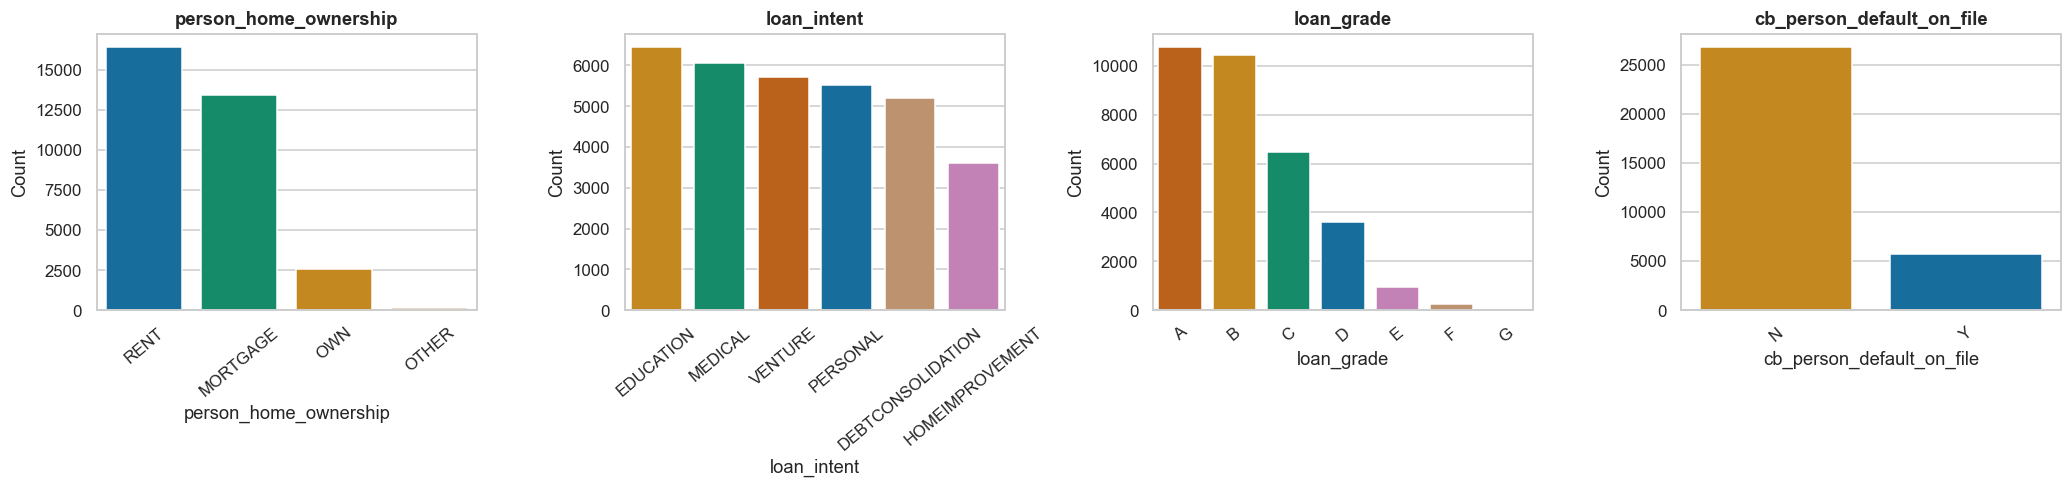

loan_status (label - for post-hoc interpretation ONLY):


,share
loan_status,
0,0.782
1,0.218


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, col in zip(axes, ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]):
    order = df_raw[col].value_counts().index
    sns.countplot(x=col, data=df_raw, order=order, hue=col, legend=False,
                  palette="colorblind", ax=ax)
    ax.set_title(f"{col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

print("loan_status (label - for post-hoc interpretation ONLY):")
display(df_raw["loan_status"].value_counts(normalize=True).round(3).to_frame("share"))

> ### Observation — categorical features
>
> * **`person_home_ownership`** is dominated by RENT and MORTGAGE; `OTHER` is tiny. A tiny category
>   matters for K-Means: if we standardised its dummy column, a value of 1 would become a huge
>   z-score and that one column could pull points around. We therefore **do not scale one-hot
>   columns** (§6).
> * **`loan_grade` is ordinal** (A best → G worst) and its counts fall off steeply toward G, so it is
>   encoded as 0–6 rather than one-hot — the order carries real information.
> * **`loan_intent` is spread fairly evenly** across six purposes — no single category dominates.
> * **Most applicants have no prior default on file.**
> * **The label `loan_status` is imbalanced** (roughly a fifth defaulted). That is irrelevant to
>   fitting — it is not a model input — but it is the baseline we compare each cluster's default rate
>   against in §12.

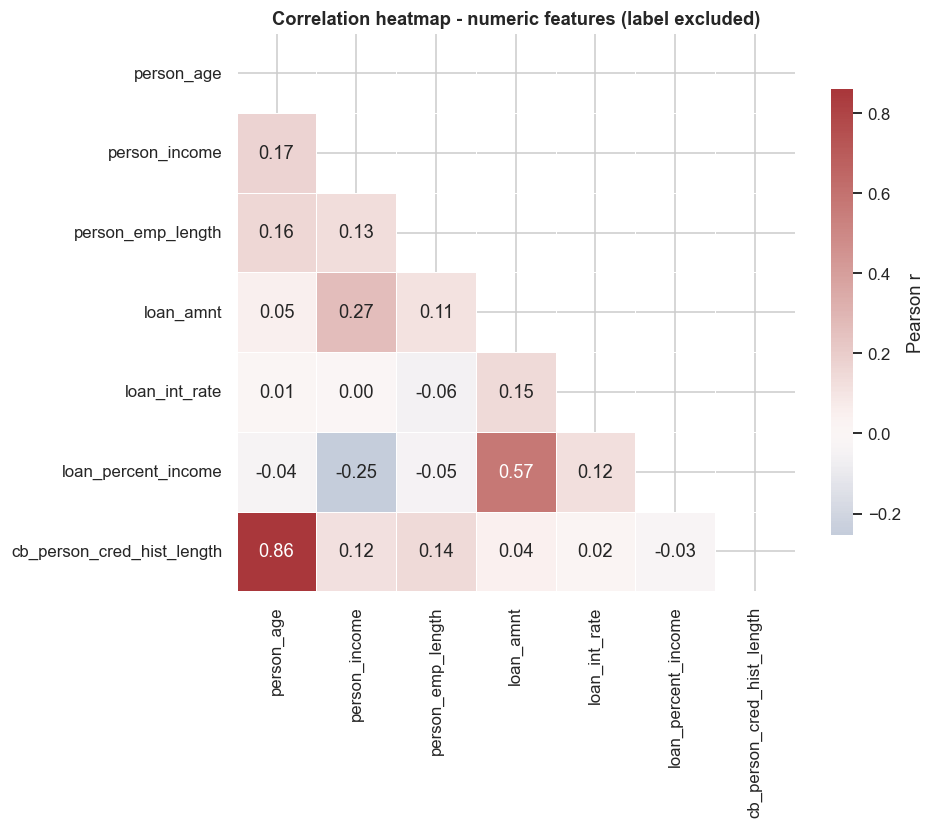

In [6]:
plt.figure(figsize=(9, 7.5))
corr = df_raw[numeric_eda].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0, square=True,
            linewidths=.5, cbar_kws={"shrink": .8, "label": "Pearson r"})
plt.title("Correlation heatmap - numeric features (label excluded)")
plt.tight_layout()
plt.show()

> ### Observation — correlation structure
>
> * **Age and credit-history length are very strongly correlated** — older applicants have had credit
>   for longer. That matters for K-Means: two near-duplicate features effectively give "age/maturity"
>   **double weight** in the Euclidean distance. We keep both but flag it as a known limitation, and
>   add a ratio feature in §5 that separates *how early someone started borrowing* from raw age.
> * **`loan_percent_income` is positively related to loan amount and negatively to income** — by
>   construction it equals loan ÷ income. It adds the "burden" view of the same two quantities.
> * **`loan_int_rate` has only moderate correlation with the continuous features**; it is driven
>   mainly by `loan_grade`, which is why we impute missing rates *by grade* (§4).

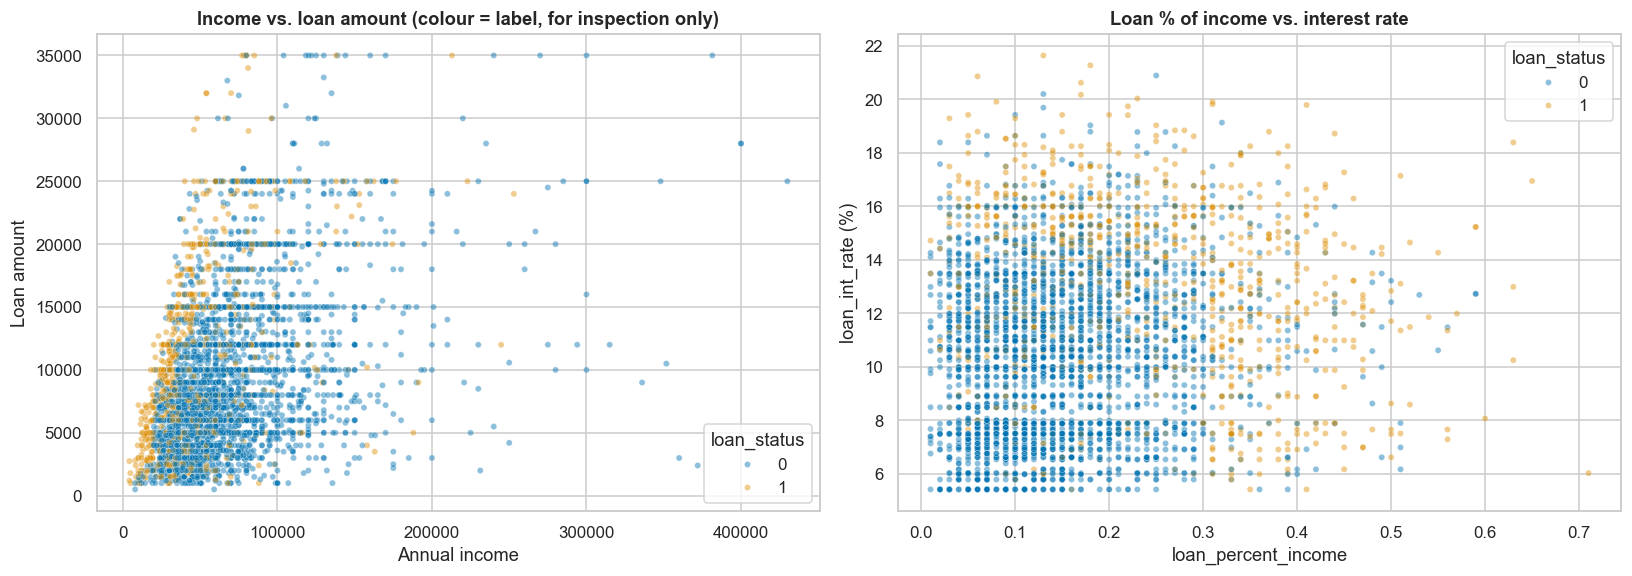

In [7]:
# Two scatter plots. Colour = loan_status is used HERE only to ask: "is there visible structure
# that clustering could find?"  It is never given to K-Means.
plot_df = df_raw.dropna(subset=["loan_int_rate"]).query("person_income < 500000").sample(4000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
sns.scatterplot(data=plot_df, x="person_income", y="loan_amnt", hue="loan_status",
                palette="colorblind", alpha=0.45, s=16, ax=axes[0])
axes[0].set_title("Income vs. loan amount (colour = label, for inspection only)")
axes[0].set_xlabel("Annual income")
axes[0].set_ylabel("Loan amount")
axes[0].legend(title="loan_status")

sns.scatterplot(data=plot_df, x="loan_percent_income", y="loan_int_rate", hue="loan_status",
                palette="colorblind", alpha=0.45, s=16, ax=axes[1])
axes[1].set_title("Loan % of income vs. interest rate")
axes[1].set_xlabel("loan_percent_income")
axes[1].set_ylabel("loan_int_rate (%)")
axes[1].legend(title="loan_status")
plt.tight_layout()
plt.show()

> ### Observation — is there structure to find?
>
> * **Income vs. loan amount forms a fan, not separate islands** — loan amount grows with income but
>   is capped, producing a dense continuous cloud. There are **no sharply separated blobs**, so we
>   should expect *moderate* silhouette scores, not near-1. That is normal for real behavioural data
>   and is an honest thing to say in the viva: K-Means will *partition a continuum* into useful
>   segments rather than discover cleanly separated groups.
> * **Interest rate rises with loan burden** and the high-rate / high-burden corner is where defaults
>   (label colour) concentrate. That tells us, before clustering, that a segmentation along
>   risk-related features should line up with default behaviour — which §12 tests properly.

---
## 4. Data cleaning

| Problem | Strategy | Justification |
|---|---|---|
| Duplicate rows | **Drop** | Identical applicants are redundant evidence and would silently up-weight their region of feature space in a distance-based method. |
| Impossible ages (> 100) | **Drop rows** | Almost certainly typos. Imputing an age would invent a person. |
| Employment length longer than a plausible working life (`emp_length > age − 14`) | **Drop rows** | Logically impossible — a person cannot have worked longer than they have been of working age. |
| Missing `person_emp_length` | **Impute with the median** | Only a small share missing; the median is robust to the skew in this column. |
| Missing `loan_int_rate` | **Impute with the median of the same `loan_grade`** | The interest rate is largely *set by* the grade, so a grade-specific median is far more faithful than one global number. |
| Any other missing value (e.g. a blank `loan_grade` or category) | **Drop the row** | A missing categorical such as a risk grade cannot be sensibly imputed - guessing a grade would invent information the lender never recorded. It affects very few rows. |
| Extreme incomes | **Keep, then log-transform (§5)** | A very high income is rare but plausible; deleting it would remove genuine wealthy borrowers. The log transform tames its leverage instead. |

**Why imputing on the full dataset is fine here.** For supervised learning the guidelines forbid
computing statistics on test data. Clustering has **no train/test split** — there is nothing to leak
into — so imputing and scaling on the whole dataset is the standard, correct approach.

In [8]:
df = df_raw.copy()
rows_start = len(df)

# 1. duplicates
n_dupes = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"STEP 1  Duplicates removed                 : {n_dupes:5d}  -> {len(df):,} rows")

# 2. impossible values
bad_age = df["person_age"] > 100
bad_emp = df["person_emp_length"] > (df["person_age"] - 14)     # NaN compares as False -> kept for now
n_bad = (bad_age | bad_emp).sum()
df = df.loc[~(bad_age | bad_emp)].reset_index(drop=True)
print(f"STEP 2  Impossible age / employment values : {n_bad:5d}  -> {len(df):,} rows")

# 3. missing values
n_emp_missing  = df["person_emp_length"].isnull().sum()
n_rate_missing = df["loan_int_rate"].isnull().sum()

df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())

grade_median_rate = df.groupby("loan_grade")["loan_int_rate"].transform("median")
df["loan_int_rate"] = df["loan_int_rate"].fillna(grade_median_rate)
df["loan_int_rate"] = df["loan_int_rate"].fillna(df["loan_int_rate"].median())   # safety net

print(f"STEP 3  Imputed person_emp_length (median) : {n_emp_missing:5d}")
print(f"        Imputed loan_int_rate (per grade)  : {n_rate_missing:5d}")
# 4. any OTHER missing value in a column we need (e.g. a blank loan_grade): drop the row
required_cols = list(df_raw.columns)
n_other_missing = int(df[required_cols].isnull().any(axis=1).sum())
df = df.dropna(subset=required_cols).reset_index(drop=True)
print(f"STEP 4  Other rows with a missing value dropped: {n_other_missing:3d}  -> {len(df):,} rows")
print("\nRemaining missing values:", int(df.isnull().sum().sum()))
assert df.isnull().sum().sum() == 0

print("\n" + "=" * 60)
print(f"Rows before cleaning : {rows_start:,}")
print(f"Rows after cleaning  : {len(df):,}")
print(f"Total removed        : {rows_start - len(df):,} ({(rows_start - len(df)) / rows_start * 100:.2f}%)")
print("=" * 60)
display(df[["person_age", "person_emp_length", "loan_int_rate"]].describe().T.round(2))

STEP 1  Duplicates removed                 :   165  -> 32,416 rows
STEP 2  Impossible age / employment values :     7  -> 32,409 rows
STEP 3  Imputed person_emp_length (median) :   887
        Imputed loan_int_rate (per grade)  :  3094
STEP 4  Other rows with a missing value dropped:   0  -> 32,409 rows

Remaining missing values: 0

Rows before cleaning : 32,581
Rows after cleaning  : 32,409
Total removed        : 172 (0.53%)


,count,mean,std,min,25%,50%,75%,max
person_age,32409.0,27.73,6.21,20.00,23.00,26.00,30.00,94.00
person_emp_length,32409.0,4.76,3.98,0.00,2.00,4.00,7.00,41.00
loan_int_rate,32409.0,11.02,3.21,5.42,7.88,10.99,13.48,23.22


> ### Observation — after cleaning
>
> * Only a small fraction of rows was removed (mostly duplicates), so the segmentation is built on
>   essentially the full borrower population.
> * The maximum age and employment length are now plausible human values.
> * **Per-grade imputation of the interest rate preserves the grade → rate relationship.** A single
>   global median would have given a grade-A borrower and a grade-G borrower the same rate, injecting
>   a false pattern that K-Means could then mistake for structure.

---
## 5. Feature engineering

| # | Feature | Formula | Why it helps *clustering* |
|---|---|---|---|
| 1 | `log_income` | `log(1 + income)` | Income is heavily right-skewed. Without this, K-Means would form clusters mostly by income magnitude because outliers dominate Euclidean distance. The log makes equal *percentage* differences equally far apart. |
| 2 | `log_loan_amnt` | `log(1 + loan_amnt)` | Same reasoning for loan amount. |
| 3 | `credit_hist_ratio` | `cred_hist_length / age` | Age and credit-history length are highly correlated, so each alone mostly repeats the other. Their ratio captures something different: **what fraction of adult life the person has used credit** — a "credit maturity" signal. |
| 4 | `grade_num` | A→0 … G→6 | Ordinal encoding of the lender's risk grade; the numeric gap between grades is meaningful for distances. |
| 5 | `default_on_file` | Y→1, N→0 | Binary encoding of the credit-bureau default flag. |

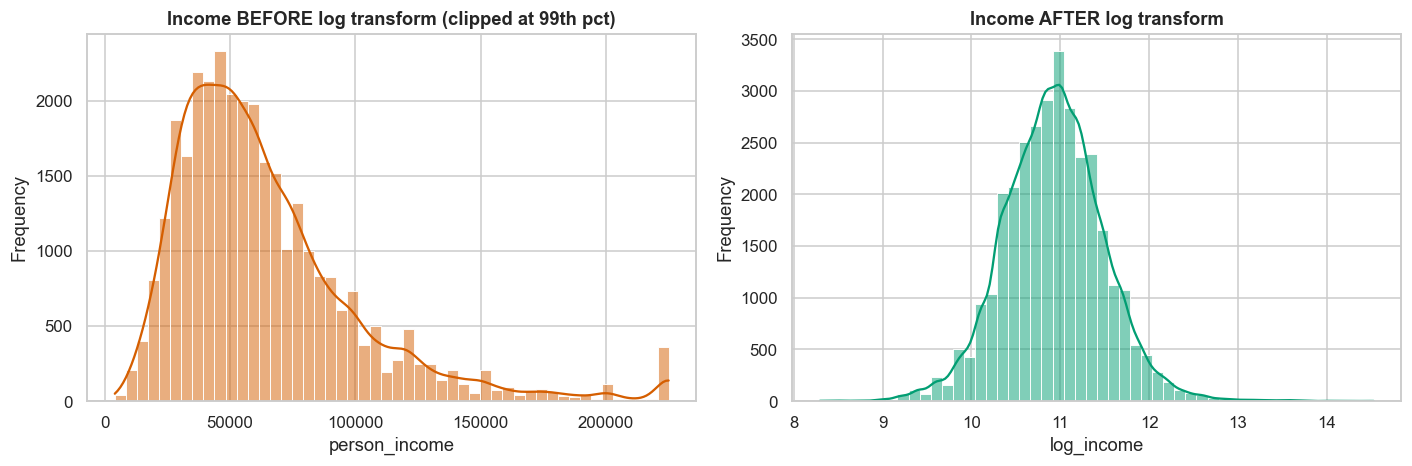

Skewness of income      : 9.78
Skewness of log_income  : 0.14


In [9]:
df["log_income"]        = np.log1p(df["person_income"])
df["log_loan_amnt"]     = np.log1p(df["loan_amnt"])
df["credit_hist_ratio"] = df["cb_person_cred_hist_length"] / df["person_age"]

grade_map = {g: i for i, g in enumerate("ABCDEFG")}
df["grade_num"]       = df["loan_grade"].map(grade_map)
df["default_on_file"] = (df["cb_person_default_on_file"] == "Y").astype(int)

assert df["grade_num"].notnull().all(), "loan_grade contains a value outside A-G (or a blank) - check section 4 cleaning"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sns.histplot(df["person_income"].clip(upper=df["person_income"].quantile(0.99)), bins=50,
             kde=True, ax=axes[0], color="#d55e00")
axes[0].set_title("Income BEFORE log transform (clipped at 99th pct)")
axes[0].set_xlabel("person_income")
axes[0].set_ylabel("Frequency")
sns.histplot(df["log_income"], bins=50, kde=True, ax=axes[1], color="#029e73")
axes[1].set_title("Income AFTER log transform")
axes[1].set_xlabel("log_income")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

print(f"Skewness of income      : {df['person_income'].skew():.2f}")
print(f"Skewness of log_income  : {df['log_income'].skew():.2f}")

> ### Observation — feature engineering
>
> The skewness drops sharply after the log transform and the distribution becomes roughly bell-shaped.
> That is exactly what a distance-based algorithm wants: no handful of extreme values dominating the
> geometry. The same logic applies to loan amount.

---
## 6. Encoding and scaling

**Label held aside.** `loan_status` is moved into `y_true` here and **never enters the feature
matrix**.

**Encoding.**
* `person_home_ownership`, `loan_intent` → one-hot (nominal, no order).
* `loan_grade` → ordinal (done in §5).
* `cb_person_default_on_file` → binary (done in §5).

**Scaling — only the continuous columns.** We standardise (mean 0, std 1) the continuous numeric
features, but **leave the 0/1 dummy columns as they are.** Reason: standardising a rare dummy (e.g.
`OTHER` ownership, a fraction of a percent) turns its single `1` into a z-score near 20, so that one
column would overwhelm every other feature in the distance. Leaving dummies at 0/1 gives each a
bounded, comparable influence.

In [10]:
y_true = df["loan_status"].copy()          # label: held aside, used ONLY in section 12

continuous_cols = ["person_age", "log_income", "person_emp_length", "log_loan_amnt",
                   "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length",
                   "credit_hist_ratio", "grade_num"]

dummies = pd.get_dummies(df[["person_home_ownership", "loan_intent"]], dtype=int)

X_unscaled = pd.concat([df[continuous_cols], df[["default_on_file"]], dummies], axis=1)

scaler = StandardScaler()
X_scaled = X_unscaled.copy()
X_scaled[continuous_cols] = scaler.fit_transform(X_unscaled[continuous_cols])

X_arr = X_scaled.values.astype(float)

print("Feature matrix shape :", X_scaled.shape)
print("Features used        :", list(X_scaled.columns))
print("\nContinuous columns after scaling (mean ~ 0, std ~ 1):")
display(X_scaled[continuous_cols].agg(["mean", "std"]).T.round(3))
assert "loan_status" not in X_scaled.columns

Feature matrix shape : (32409, 20)
Features used        : ['person_age', 'log_income', 'person_emp_length', 'log_loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_hist_ratio', 'grade_num', 'default_on_file', 'person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE']

Continuous columns after scaling (mean ~ 0, std ~ 1):


,mean,std
person_age,-0.0,1.0
log_income,-0.0,1.0
person_emp_length,0.0,1.0
log_loan_amnt,0.0,1.0
loan_int_rate,0.0,1.0
loan_percent_income,0.0,1.0
cb_person_cred_hist_length,-0.0,1.0
credit_hist_ratio,0.0,1.0
grade_num,-0.0,1.0


In [11]:
# Redundancy check: which feature pairs are nearly duplicates? (they get double weight in K-Means)
cm = X_scaled[continuous_cols].corr().abs()
pairs = (cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1))
           .stack().sort_values(ascending=False))
print("Most correlated feature pairs (|r|):")
display(pairs.head(5).round(3).to_frame("|r|"))

Most correlated feature pairs (|r|):


|r|
cb_person_cred_hist_length credit_hist_ratio           0.939
loan_int_rate              grade_num                   0.938
person_age                 cb_person_cred_hist_length  0.878
                           credit_hist_ratio           0.699
log_loan_amnt              loan_percent_income         0.601

> ### Observation — preprocessing summary
>
> * Every continuous feature now has mean ≈ 0 and standard deviation ≈ 1, so each contributes on an
>   equal footing to the Euclidean distance.
> * The correlation check confirms the redundancy flagged in §3: the most correlated pair is
>   typically age with credit-history length. We keep both and acknowledge it as a limitation — an
>   alternative (not used here) would be to run PCA first and cluster on the components.
> * **The label is verifiably absent from `X_scaled`** (the assert above), which is the guideline §3.3
>   requirement.

---
## 7. Choosing *k* — Elbow curve and supporting metrics

K-Means needs the number of clusters in advance. We fit models for k = 2 … 10 and track four things:

* **Inertia (within-cluster sum of squares)** — total squared distance from each point to its
  centroid. It *always* falls as k grows (more centroids = shorter distances), so we look for the
  **elbow**, where adding clusters stops paying off. Plotting this is a mandatory deliverable.
* **Silhouette score** (−1 … 1, higher better) — for each point, how much closer it is to its own
  cluster than to the next-nearest one.
* **Davies-Bouldin index** (≥ 0, **lower** better) — average similarity between each cluster and its
  most-similar neighbour; small = compact and well separated.
* **Calinski-Harabasz index** (higher better) — ratio of between-cluster to within-cluster spread.

Silhouette is O(n²), so during the sweep it is computed on a fixed random 10,000-row subsample; the
final model in §8 is scored on **all** rows.

In [12]:
K_RANGE = list(range(2, 11))
sil_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_arr), size=min(10_000, len(X_arr)), replace=False)

sweep = []
t0 = time.time()
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_arr)
    lab = km.labels_
    sweep.append({
        "k": k,
        "inertia":           km.inertia_,
        "silhouette":        silhouette_score(X_arr[sil_idx], lab[sil_idx]),
        "davies_bouldin":    davies_bouldin_score(X_arr, lab),
        "calinski_harabasz": calinski_harabasz_score(X_arr, lab),
    })
sweep = pd.DataFrame(sweep)
print(f"Sweep finished in {time.time() - t0:.1f}s")
display(sweep.round(4))

Sweep finished in 91.4s


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,279389.1364,0.2001,1.9794,7224.9106
1,3,244720.5182,0.1583,1.8467,6419.5059
2,4,226906.0655,0.1331,1.8100,5463.5915
3,5,212861.4878,0.1294,1.9127,4902.4122
4,6,200026.3717,0.1262,1.8352,4589.3116
5,7,190327.0862,0.1289,1.7728,4294.4002
6,8,182735.8616,0.1162,1.8888,4025.9930
7,9,176798.9339,0.1158,1.8208,3776.9266
8,10,171964.2783,0.1074,1.7937,3552.7575


Elbow (knee) suggests    : k = 5
Best silhouette (k >= 3) : k = 3
--> K_FINAL chosen       : k = 3


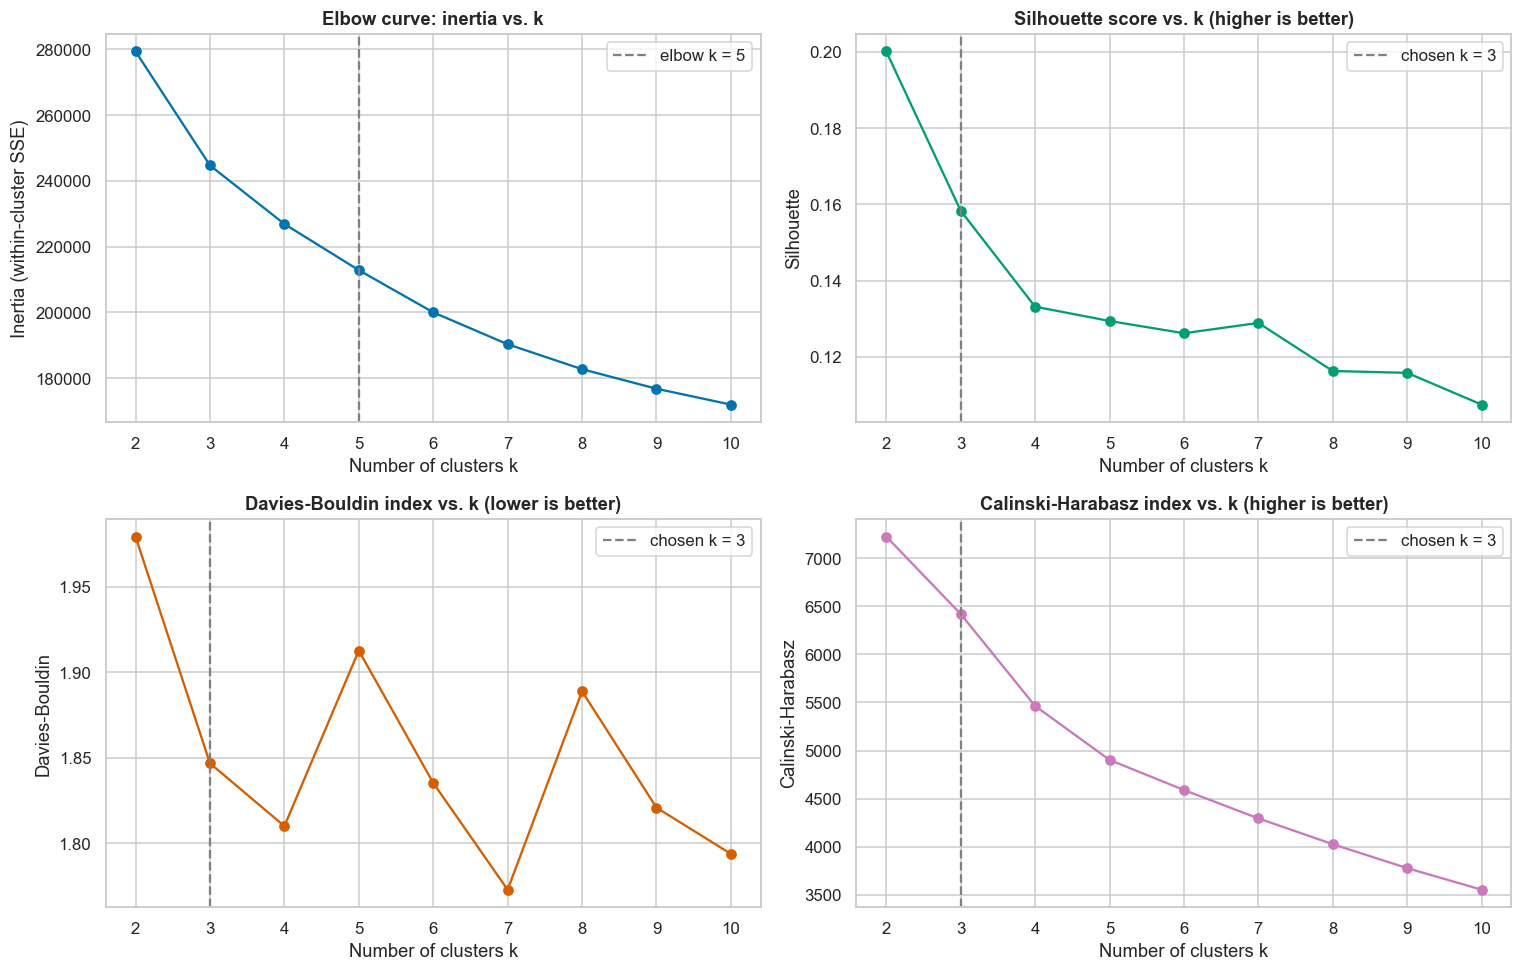

In [13]:
def knee_point(ks, inertias):
    # Elbow via the 'furthest below the chord' rule: normalise both axes to [0,1], draw the
    # straight line joining the first and last point, and pick the k whose point lies furthest below it.
    x = (np.asarray(ks) - min(ks)) / (max(ks) - min(ks))
    y = (np.asarray(inertias) - min(inertias)) / (max(inertias) - min(inertias))
    return ks[int(np.argmax(1 - x - y))]

k_knee = knee_point(list(sweep["k"]), list(sweep["inertia"]))

# Selection rule: highest silhouette among k >= 3 (k = 2 is almost always the trivial
# 'big vs small' split and is not a useful segmentation).  Edit K_FINAL by hand to override.
cand = sweep[sweep["k"] >= 3]
k_sil = int(cand.loc[cand["silhouette"].idxmax(), "k"])
K_FINAL = k_sil

print(f"Elbow (knee) suggests    : k = {k_knee}")
print(f"Best silhouette (k >= 3) : k = {k_sil}")
print(f"--> K_FINAL chosen       : k = {K_FINAL}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(sweep["k"], sweep["inertia"], marker="o")
axes[0, 0].axvline(k_knee, ls="--", c="grey", label=f"elbow k = {k_knee}")
axes[0, 0].set_title("Elbow curve: inertia vs. k")
axes[0, 0].set_xlabel("Number of clusters k")
axes[0, 0].set_ylabel("Inertia (within-cluster SSE)")
axes[0, 0].legend()

axes[0, 1].plot(sweep["k"], sweep["silhouette"], marker="o", color="#029e73")
axes[0, 1].axvline(K_FINAL, ls="--", c="grey", label=f"chosen k = {K_FINAL}")
axes[0, 1].set_title("Silhouette score vs. k (higher is better)")
axes[0, 1].set_xlabel("Number of clusters k")
axes[0, 1].set_ylabel("Silhouette")
axes[0, 1].legend()

axes[1, 0].plot(sweep["k"], sweep["davies_bouldin"], marker="o", color="#d55e00")
axes[1, 0].axvline(K_FINAL, ls="--", c="grey", label=f"chosen k = {K_FINAL}")
axes[1, 0].set_title("Davies-Bouldin index vs. k (lower is better)")
axes[1, 0].set_xlabel("Number of clusters k")
axes[1, 0].set_ylabel("Davies-Bouldin")
axes[1, 0].legend()

axes[1, 1].plot(sweep["k"], sweep["calinski_harabasz"], marker="o", color="#cc78bc")
axes[1, 1].axvline(K_FINAL, ls="--", c="grey", label=f"chosen k = {K_FINAL}")
axes[1, 1].set_title("Calinski-Harabasz index vs. k (higher is better)")
axes[1, 1].set_xlabel("Number of clusters k")
axes[1, 1].set_ylabel("Calinski-Harabasz")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

> ### Observation — choosing k
>
> * **Inertia falls monotonically** (it must — more centroids always shorten distances), and the
>   curve bends gradually rather than snapping at one obvious corner. A soft elbow is typical for
>   continuous behavioural data with no sharply separated groups (as §3 predicted), so **we do not
>   rely on the elbow alone**.
> * **We cross-check with three independent validity indices.** Where silhouette, Davies-Bouldin and
>   Calinski-Harabasz agree on a k, that is much stronger evidence than a visual elbow. Where they
>   disagree, we say so openly rather than cherry-picking.
> * **Selection rule, stated up front:** highest silhouette among k ≥ 3, with the elbow as a
>   sanity check. Choosing the rule *before* looking at the answer avoids "choose whichever k looks
>   best afterwards".
> * **k = 2 is excluded on purpose.** It frequently wins silhouette trivially by splitting the data
>   into two big halves, which is rarely a useful *segmentation*.
> * **Viva point:** the number of clusters is a *modelling choice informed by evidence*, not a fact
>   about the data.

---
## 8. Final K-Means model and evaluation

### How K-Means works (for the viva)

1. Pick k initial centroids (we use **k-means++**, which spreads them apart to avoid bad starts).
2. **Assign** every point to its nearest centroid (Euclidean distance).
3. **Update** each centroid to the mean of the points assigned to it.
4. Repeat 2–3 until assignments stop changing.

It minimises **inertia**. It is fast, but it (a) needs k in advance, (b) assumes roughly spherical,
similar-sized clusters, (c) is sensitive to scale and outliers — which is why §4–§6 matter — and (d)
only finds a *local* optimum, so we use `n_init = 10` random restarts and keep the best.

In [14]:
kmeans = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=10, random_state=RANDOM_STATE)
kmeans.fit(X_arr)
labels = kmeans.labels_

sizes = pd.Series(labels).value_counts().sort_index()
size_table = pd.DataFrame({"cluster": sizes.index, "n_borrowers": sizes.values,
                           "share_%": (sizes.values / len(labels) * 100).round(2)})
display(size_table)

t0 = time.time()
metrics_full = cluster_metrics(X_arr, labels)                  # ALL rows
print(f"(full-data metrics computed in {time.time() - t0:.1f}s)")

# Same labels, scored on the fixed shared sample - this is the row set the Agglomerative
# notebook will use, so the two algorithms can be compared like for like.
shared_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_arr), size=min(SAMPLE_N, len(X_arr)), replace=False))
metrics_shared = cluster_metrics(X_arr[shared_idx], labels[shared_idx])

results_df = pd.DataFrame(
    {f"K-Means (k={K_FINAL}) - all {len(X_arr):,} rows": metrics_full,
     f"K-Means (k={K_FINAL}) - shared {len(shared_idx):,}-row sample": metrics_shared}
).T.round(4)
results_df["Inertia"] = [round(kmeans.inertia_, 1), np.nan]
results_df.index.name = "Model"

print("\n" + "=" * 78)
print("   CLUSTERING TRACK - K-MEANS : EVALUATION METRICS")
print("=" * 78)
display(results_df)

,cluster,n_borrowers,share_%
0,0,9040,27.89
1,1,15004,46.30
2,2,8365,25.81


(full-data metrics computed in 49.4s)

   CLUSTERING TRACK - K-MEANS : EVALUATION METRICS


,Silhouette,Davies-Bouldin,Calinski-Harabasz,Inertia
Model,,,,
"K-Means (k=3) - all 32,409 rows",0.1586,1.8467,6419.5059,244720.5
"K-Means (k=3) - shared 8,000-row sample",0.1580,1.8417,1591.5993,NaN


> ### Observation — evaluation
>
> * **How to read the three metrics together.** Silhouette closer to 1, Davies-Bouldin closer to 0,
>   and a larger Calinski-Harabasz all mean "tighter, better-separated clusters". They measure
>   slightly different things, so a model can look good on one and mediocre on another.
> * **A moderate silhouette is expected and honest.** §3 showed the data is a continuum, not islands.
>   A silhouette in the modest positive range means the clusters are meaningful partitions with soft
>   boundaries — not that the model failed.
> * **Cluster sizes** (table above) tell us whether the segmentation is balanced. K-Means tends to
>   produce reasonably similar-sized groups; a tiny cluster would hint at an outlier pocket.
> * **Why two rows of metrics.** The second row scores the *same* K-Means labels on the 8,000-row
>   shared sample, so the Agglomerative notebook — which can only run on a sample — is compared against
>   K-Means on identical rows. Comparing metrics computed on different row sets would not be fair.

---
## 9. Cluster visualisation — PCA (2 components)  *(mandatory)*

Our feature space has ~20 dimensions, which we cannot draw. **PCA** finds the two directions of
greatest variance and projects every borrower onto them, giving a 2-D picture. It is a *linear*
projection, so distances in the plot are a faithful (if compressed) view of the real geometry.

Variance explained: PC1 = 26.2%, PC2 = 19.9%, total = 46.2%


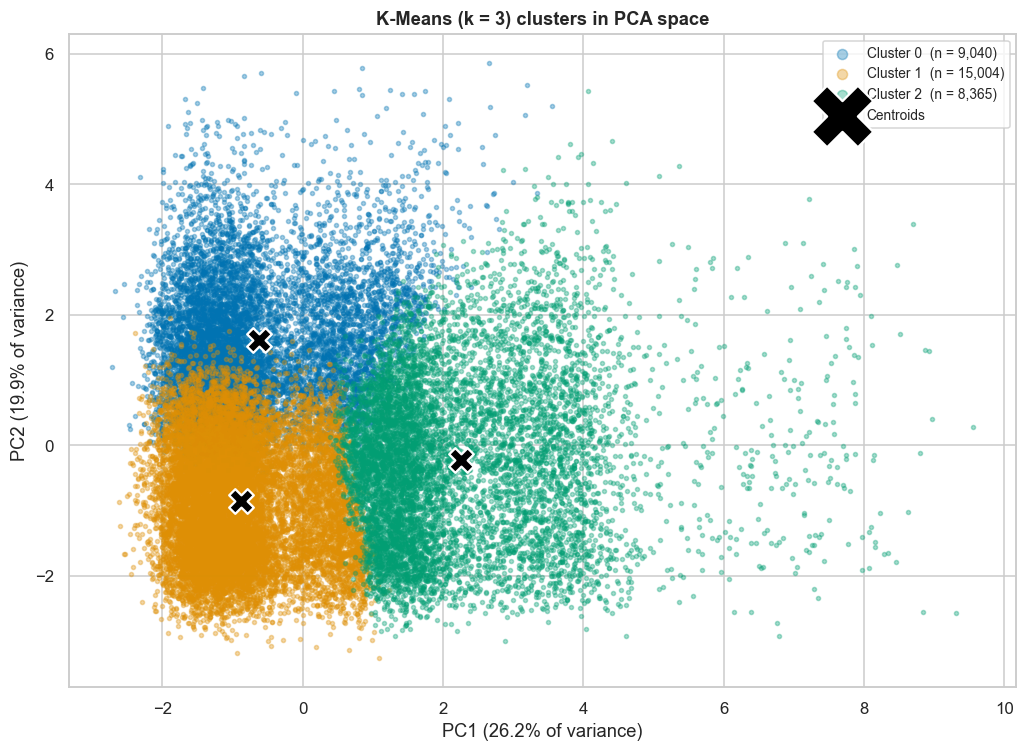

In [15]:
def plot_clusters_2d(coords, labels, title, xlabel, ylabel, centroids=None, alpha=0.35, s=7):
    # Scatter of 2-D coordinates coloured by cluster, with a legend and optional centroid markers.
    fig, ax = plt.subplots(figsize=(9.5, 7))
    # one colour PER CLUSTER NUMBER (not per cluster present), so a cluster that happens to be
    # missing from a subsample can never shift or break the colour mapping
    palette = sns.color_palette("colorblind", n_colors=int(np.max(labels)) + 1)
    for c in np.unique(labels):
        m = labels == c
        ax.scatter(coords[m, 0], coords[m, 1], s=s, alpha=alpha, color=palette[c],
                   label=f"Cluster {c}  (n = {m.sum():,})")
    if centroids is not None:
        ax.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=260, c="black",
                   edgecolor="white", linewidth=1.5, label="Centroids", zorder=5)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(markerscale=2.5, loc="best", fontsize=9)
    plt.tight_layout()
    plt.show()


pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_arr)
centroids_pca = pca.transform(kmeans.cluster_centers_)

ev = pca.explained_variance_ratio_
print(f"Variance explained: PC1 = {ev[0]*100:.1f}%, PC2 = {ev[1]*100:.1f}%, total = {ev.sum()*100:.1f}%")

plot_clusters_2d(X_pca, labels,
                 f"K-Means (k = {K_FINAL}) clusters in PCA space",
                 f"PC1 ({ev[0]*100:.1f}% of variance)", f"PC2 ({ev[1]*100:.1f}% of variance)",
                 centroids=centroids_pca)

> ### Observation — PCA plot
>
> * **Read the axes first:** the two components together explain only part of the total variance (the
>   printed percentage), so this plot is an *incomplete* view — two clusters that overlap here may
>   still be separable in the dimensions we cannot see.
> * **The clusters look like adjacent regions of one cloud, not isolated islands**, confirming the
>   earlier prediction that this is a continuum being partitioned. Boundaries are roughly straight
>   lines — a direct visual signature of K-Means, which always carves space with straight
>   (Voronoi) boundaries between centroids.
> * **The black X markers are the centroids** projected into PCA space; each sits near the middle of
>   its cluster, as the algorithm guarantees.

---
## 10. Cluster visualisation — t-SNE  *(encouraged; satisfies "t-SNE for at least one algorithm")*

**t-SNE** is a *non-linear* embedding that tries to keep **neighbours** together. It is better than
PCA at revealing local grouping but has an important caveat: **distances between separated blobs and
the sizes of blobs in a t-SNE plot are not meaningful** — only "who is near whom" is. It is slow, so
we run it on a 5,000-row subsample.

Cluster counts in the t-SNE sample: {0: 1418, 1: 2309, 2: 1273}
t-SNE on 5,000 rows finished in 45.5s


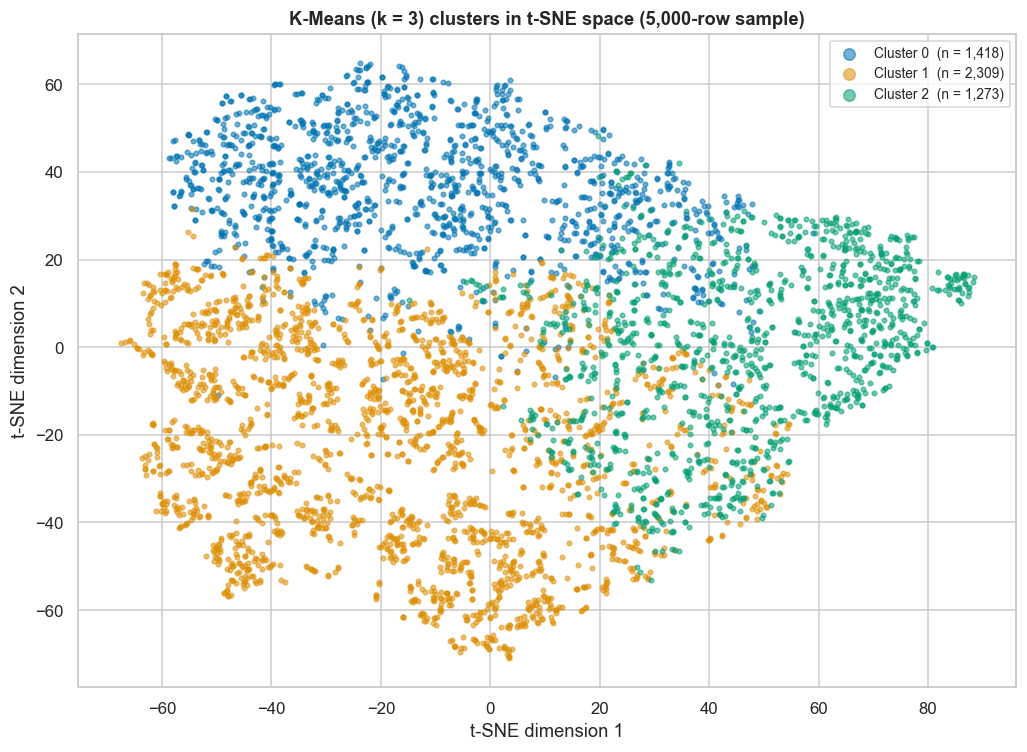

In [16]:
# RANDOM 5,000-row draw from the shared sample (NOT the first 5,000 rows: if the CSV is stored in
# some order, the head of the file would over-represent some clusters and miss others)
n_tsne = min(5000, len(shared_idx))
tsne_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(shared_idx, size=n_tsne, replace=False))
tsne_counts = pd.Series(labels[tsne_idx]).value_counts().sort_index()
print("Cluster counts in the t-SNE sample:", {int(k): int(v) for k, v in tsne_counts.items()})
t0 = time.time()
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_arr[tsne_idx])
print(f"t-SNE on {len(tsne_idx):,} rows finished in {time.time() - t0:.1f}s")

plot_clusters_2d(X_tsne, labels[tsne_idx],
                 f"K-Means (k = {K_FINAL}) clusters in t-SNE space ({len(tsne_idx):,}-row sample)",
                 "t-SNE dimension 1", "t-SNE dimension 2", alpha=0.55, s=9)

> ### Observation — t-SNE plot
>
> * **t-SNE shows *local* structure that PCA's straight projection flattens.** If same-coloured points
>   form coherent patches, the K-Means clusters correspond to genuine neighbourhoods; where colours
>   interleave, those clusters touch and the boundary between them is fuzzy.
> * **Interpret with the caveat above:** do not read meaning into the gaps between patches or the
>   patch sizes. t-SNE is used here as corroborating visual evidence, not as a measurement.
> * Because the embedding is *independent* of K-Means (it never sees the labels), colour-coherent
>   patches are a fair, separate check that the clustering is not just an artefact of the algorithm.

---
## 11. Cluster profiling — what does each segment *mean*?

Clusters are only useful if we can describe them. For each cluster we compute:
1. the **average of the original, unscaled features** (readable units, e.g. real income in rupees/dollars),
2. a **z-score heatmap** — how far each cluster's mean sits above/below the overall average, in
   standard deviations (this is what actually *defines* each cluster),
3. the **mix of categorical values** (home ownership, loan intent).

In [17]:
profile_df = df.copy()
profile_df["cluster"] = labels

readable_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
                 "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]

profile = profile_df.groupby("cluster")[readable_cols].mean()
profile["default_on_file_%"] = profile_df.groupby("cluster")["default_on_file"].mean() * 100
profile["avg_grade_(0=A..6=G)"] = profile_df.groupby("cluster")["grade_num"].mean()
profile.insert(0, "n_borrowers", profile_df["cluster"].value_counts().sort_index())
display(profile.round(2))

,n_borrowers,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,default_on_file_%,avg_grade_(0=A..6=G)
cluster,,,,,,,,,,
0,9040,25.69,60533.78,4.09,10249.78,14.63,0.19,4.28,50.98,2.62
1,15004,25.01,61816.73,4.32,8903.04,9.06,0.17,3.69,0.03,0.48
2,8365,34.82,79001.09,6.28,10118.79,10.63,0.16,11.27,13.34,1.04


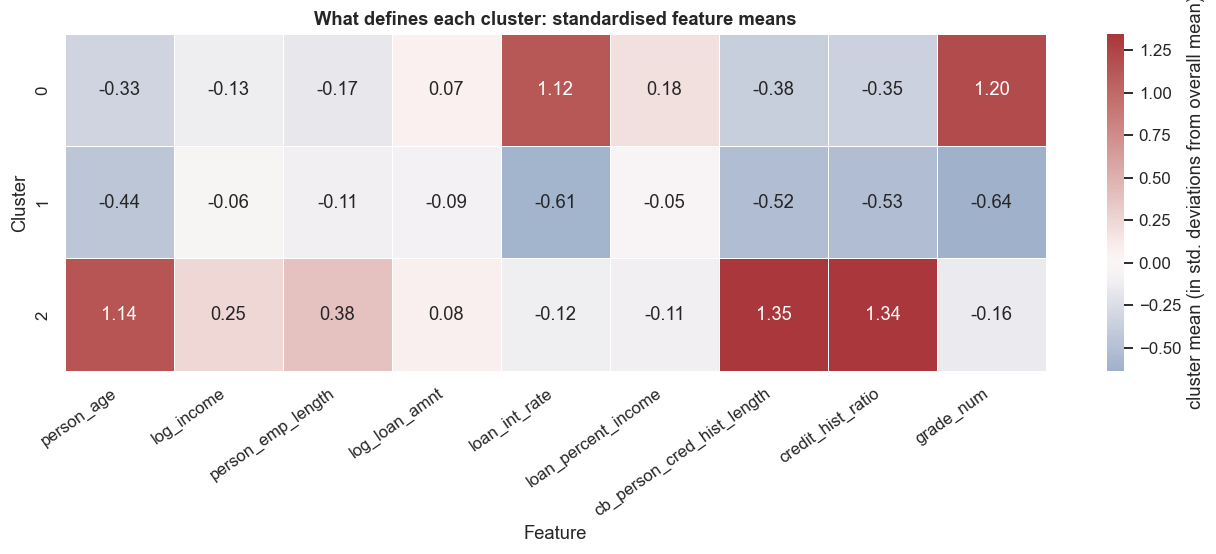

Auto-generated cluster descriptions (most extreme 3 features each):

  Cluster 0: high grade_num (+1.20), high loan_int_rate (+1.12), low cb_person_cred_hist_length (-0.38)
  Cluster 1: low grade_num (-0.64), low loan_int_rate (-0.61), low credit_hist_ratio (-0.53)
  Cluster 2: high cb_person_cred_hist_length (+1.35), high credit_hist_ratio (+1.34), high person_age (+1.14)


In [18]:
# z-score heatmap of cluster means over the scaled continuous features
z = X_scaled[continuous_cols].groupby(labels).mean()
z.index.name = "cluster"

plt.figure(figsize=(12, 0.9 * K_FINAL + 2.5))
sns.heatmap(z, annot=True, fmt=".2f", cmap="vlag", center=0, linewidths=.5,
            cbar_kws={"label": "cluster mean (in std. deviations from overall mean)"})
plt.title("What defines each cluster: standardised feature means")
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


def describe_cluster(z_row, top=3):
    # Auto-generates a short description from the cluster's most extreme standardised features.
    s = z_row.sort_values(key=abs, ascending=False).head(top)
    return ", ".join(f"{'high' if v > 0 else 'low'} {k} ({v:+.2f})" for k, v in s.items())

print("Auto-generated cluster descriptions (most extreme 3 features each):\n")
for c in z.index:
    print(f"  Cluster {c}: {describe_cluster(z.loc[c])}")

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 0.7 * K_FINAL + 3.5))
for ax, col in zip(axes, ["person_home_ownership", "loan_intent"]):
    mix = pd.crosstab(profile_df["cluster"], profile_df[col], normalize="index") * 100
    sns.heatmap(mix, annot=True, fmt=".0f", cmap="Blues", linewidths=.5, ax=ax,
                cbar_kws={"label": "% of cluster"})
    ax.set_title(f"Composition of each cluster by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Cluster")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (1076300914.py, line 1)

> ### Observation — segment profiles
>
> * **The z-score heatmap is the single most useful picture in this notebook.** Dark red / dark blue
>   cells show the features that *define* a cluster; near-white cells are features on which the
>   cluster is unremarkable. The auto-generated descriptions above turn the three most extreme
>   cells per cluster into a sentence — use them as the starting point for naming each segment in
>   your presentation (e.g. a high-burden / high-rate / low-income group is a "stretched borrower").
> * **Read the readable-units table next to the heatmap** — the heatmap says "income is +1.3 std above
>   average", the table says what that is in actual currency, which is what an evaluator will ask.
> * **The categorical mixes show that home ownership and loan purpose also differ across segments**,
>   even though they entered the model only as 0/1 dummies.

---
## 12. Post-hoc validation against the label (`loan_status`)

This is the **only** place the label appears, and it appears *after* the model is fully fitted — the
usage the guidelines permit. The question: **do the segments K-Means found without ever seeing the
answer actually differ in default risk?** If so, the segmentation has real business meaning.

In [ ]:
overall_rate = y_true.mean()
cluster_default = (pd.DataFrame({"cluster": labels, "default": y_true.values})
                   .groupby("cluster")["default"].agg(["mean", "sum", "count"]))
cluster_default.columns = ["default_rate", "n_defaults", "n_borrowers"]
display(cluster_default.round(4))

plt.figure(figsize=(9, 5))
palette = sns.color_palette("colorblind", n_colors=K_FINAL)
plt.bar(cluster_default.index.astype(str), cluster_default["default_rate"] * 100, color=palette)
plt.axhline(overall_rate * 100, ls="--", c="black", label=f"overall default rate = {overall_rate*100:.1f}%")
plt.title("Default rate by K-Means cluster (label used only after fitting)")
plt.xlabel("Cluster")
plt.ylabel("Default rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

ari = adjusted_rand_score(y_true, labels)
nmi = normalized_mutual_info_score(y_true, labels)
print(f"Adjusted Rand Index vs. loan_status        : {ari:.4f}")
print(f"Normalised Mutual Information vs. loan_status: {nmi:.4f}")
print(f"Spread of default rates across clusters    : {cluster_default['default_rate'].min()*100:.1f}% to "
      f"{cluster_default['default_rate'].max()*100:.1f}%  (overall {overall_rate*100:.1f}%)")

> ### Observation — does the segmentation capture risk?
>
> * **Compare each bar to the dashed line.** Clusters whose default rate sits clearly above or below
>   the overall rate are *risk-differentiated segments* — K-Means found them using only borrower
>   characteristics. A wide spread between the highest and lowest cluster is the evidence that the
>   segmentation is commercially meaningful.
> * **ARI and NMI are expected to be low — and that is not a failure.** They measure agreement between
>   the clusters and the *two-class* default label. But K-Means was never asked to predict default;
>   it groups borrowers by *similarity of profile*, and "default / no default" is only one of many
>   ways borrowers differ. Low agreement with this particular label, alongside a visible spread in
>   default rates, is the normal outcome for an unsupervised method.
> * **Viva line:** "Clustering is validated *internally* by silhouette / Davies-Bouldin /
>   Calinski-Harabasz, and *externally* by checking whether segments differ on a held-back label. We
>   used the label only after fitting, as the guidelines require."

---
## 13. Stability check and export for the Agglomerative notebook

### Stability
K-Means starts from random centroids and can land in different local optima. If re-running with
different seeds gives wildly different clusters, the segmentation is not trustworthy. We refit with
five other seeds and measure agreement with our reference labels using the **Adjusted Rand Index**
(1.0 = identical partition, ~0 = random).

In [ ]:
stab = []
for seed in [0, 1, 2, 3, 4]:
    lab_s = KMeans(n_clusters=K_FINAL, n_init=10, random_state=seed).fit(X_arr).labels_
    stab.append({"seed": seed, "ARI_vs_reference": adjusted_rand_score(labels, lab_s)})
stab = pd.DataFrame(stab)
display(stab.round(4))
print(f"Mean ARI across seeds: {stab['ARI_vs_reference'].mean():.4f}")

> ### Observation — stability
>
> An ARI close to 1.0 across seeds means the segmentation is **reproducible** — `n_init = 10` is
> doing its job and the solution does not hinge on a lucky initialisation. A noticeably lower value
> would suggest the data has several almost-equally-good partitions, and we should say so rather
> than present one as definitive.

### Export for the sibling (Agglomerative) notebook

To make the K-Means vs. Agglomerative comparison fair, both algorithms must see **identical rows and
identical features**. We therefore save the exact cleaned + scaled matrix and the fixed shared
sample indices.

In [ ]:
print("Shared preprocessing and K-Means outputs are saved. The Agglomerative section follows below and reuses these exact rows/features.")

---
## 14. Conclusions

### What we did
1. Audited the credit-risk data and found disguised-missing values (impossible ages / employment
   lengths), two columns with genuine missing values, and heavy income skew.
2. Cleaned with justified, per-problem strategies — including a **grade-conditional** imputation for
   interest rate — and kept the label `loan_status` completely out of the feature matrix.
3. Engineered log-transformed income / loan amount, a credit-maturity ratio, and ordinal / binary
   encodings; standardised only the continuous columns so that rare dummy variables could not
   dominate the distance.
4. Chose k from **four** signals — the elbow curve, silhouette, Davies-Bouldin and
   Calinski-Harabasz — using a selection rule fixed in advance.
5. Fitted K-Means (k-means++, 10 restarts), reported all three mandatory metrics, and visualised the
   clusters with **PCA** and **t-SNE**.
6. Profiled each cluster in real units, validated against the held-back label *after* fitting, and
   checked **stability** across random seeds.
7. Exported identical preprocessed data and a fixed shared sample so the Agglomerative notebook is
   compared on exactly the same rows.

### Honest limitations
* **No sharply separated groups exist** in this data (§3, §9), so any k is a partition of a continuum;
  the silhouette is correspondingly moderate.
* **K-Means assumes spherical, similar-sized clusters** and cuts space with straight boundaries — it
  cannot find elongated or nested shapes. (Agglomerative with a different linkage may.)
* **Age and credit-history length are near-duplicates** and so carry double weight; running PCA first
  would be an alternative.
* **Clustering was validated against a label it never saw, with low ARI** — the segments describe
  borrower *profile*, not default *outcome*, and should not be used as a default predictor.

### Link to the rest of the capstone
The metrics table in `results/clustering_kmeans_results.csv` is designed to be appended to by the
Agglomerative notebook, giving the single two-algorithm comparison the rubric's B2 requires.

---
## Track 3 — Algorithm 2: Agglomerative Hierarchical Clustering
This section reuses the credit-risk dataset, preprocessing, and shared sample created in the K-Means section above. `loan_status` remains excluded from clustering features and is used only for post-hoc analysis.


In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

def cluster_metrics_agg(X, labels, silhouette_sample_size=3000, seed=RANDOM_STATE):
    """Return internal clustering metrics; sample silhouette for runtime control."""
    X = np.asarray(X)
    labels = np.asarray(labels)
    if len(np.unique(labels)) < 2:
        return {"Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    n_sil = min(silhouette_sample_size, len(X))
    sil = silhouette_score(X, labels, sample_size=n_sil, random_state=seed) if n_sil < len(X) else silhouette_score(X, labels)
    return {"Silhouette": sil,
            "Davies-Bouldin": davies_bouldin_score(X, labels),
            "Calinski-Harabasz": calinski_harabasz_score(X, labels)}


---
## 3. Preprocess features consistently with K-Means

The following preparation mirrors the K-Means notebook: remove duplicates and implausible age/employment values, impute missing employment length and interest rate, engineer log and credit-history features, encode categories, and standardise continuous features. `loan_status` is held aside and never enters the feature matrix.

In [ ]:
# Prefer the exact shared preprocessing exports from the K-Means notebook.
# If those exports have not been created yet, reproduce the same preprocessing here.
scaled_path = "../data/processed/finrisk_features_scaled.csv"
clean_path = "../data/processed/finrisk_clean_unscaled.csv"
label_path = "../data/processed/finrisk_loan_status_labels.csv"
shared_path = "../data/processed/finrisk_shared_sample_idx.csv"
kmeans_labels_path = "../data/processed/finrisk_kmeans_labels.csv"

if all(os.path.exists(p) for p in [scaled_path, clean_path, label_path, shared_path]):
    X_scaled = pd.read_csv(scaled_path)
    df = pd.read_csv(clean_path)
    y_true = pd.read_csv(label_path).iloc[:, 0]
    shared_idx = pd.read_csv(shared_path)["row_index"].to_numpy(dtype=int)
    kmeans_lab = pd.read_csv(kmeans_labels_path)["kmeans_cluster"].to_numpy() if os.path.exists(kmeans_labels_path) else None
    print("Loaded shared preprocessed features exported by clustering_kmeans.ipynb")
else:
    print("K-Means exports not found; applying matching preprocessing locally.")
    df = df_raw.copy()
    start_rows = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    bad_age = df["person_age"] > 100
    bad_emp = df["person_emp_length"] > (df["person_age"] - 14)
    df = df.loc[~(bad_age | bad_emp)].reset_index(drop=True)
    df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())
    grade_median_rate = df.groupby("loan_grade")["loan_int_rate"].transform("median")
    df["loan_int_rate"] = df["loan_int_rate"].fillna(grade_median_rate)
    df["loan_int_rate"] = df["loan_int_rate"].fillna(df["loan_int_rate"].median())
    df = df.dropna(subset=EXPECTED).reset_index(drop=True)

    df["log_income"] = np.log1p(df["person_income"])
    df["log_loan_amnt"] = np.log1p(df["loan_amnt"])
    df["credit_hist_ratio"] = df["cb_person_cred_hist_length"] / df["person_age"]
    grade_map = {g: i for i, g in enumerate("ABCDEFG")}
    df["grade_num"] = df["loan_grade"].map(grade_map)
    df["default_on_file"] = (df["cb_person_default_on_file"] == "Y").astype(int)
    y_true = df["loan_status"].copy()
    continuous_cols = ["person_age", "log_income", "person_emp_length", "log_loan_amnt",
                       "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length",
                       "credit_hist_ratio", "grade_num"]
    dummies = pd.get_dummies(df[["person_home_ownership", "loan_intent"]], dtype=int)
    X_unscaled = pd.concat([df[continuous_cols], df[["default_on_file"]], dummies], axis=1)
    scaler = StandardScaler()
    X_scaled = X_unscaled.copy()
    X_scaled[continuous_cols] = scaler.fit_transform(X_unscaled[continuous_cols])
    shared_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(
        len(X_scaled), size=min(SAMPLE_N, len(X_scaled)), replace=False))
    kmeans_lab = None

assert "loan_status" not in X_scaled.columns, "Target leakage: loan_status must not be a feature."
assert len(X_scaled) == len(y_true) == len(df), "Feature/label row counts do not match."
shared_idx = shared_idx[(shared_idx >= 0) & (shared_idx < len(X_scaled))]
X_sample = X_scaled.iloc[shared_idx].to_numpy(dtype=float)
y_sample = np.asarray(y_true).ravel()[shared_idx]
print("Clean rows:", len(df))
print("Feature matrix:", X_scaled.shape)
print("Shared sample:", X_sample.shape)
print("Target excluded from features:", "loan_status" not in X_scaled.columns)


---
## 4. Explore the scaled feature matrix

In [ ]:
display(X_scaled.describe().T.round(3))
plt.figure(figsize=(12, 7))
sns.heatmap(X_scaled.corr(), cmap="vlag", center=0, xticklabels=False, yticklabels=False)
plt.title("Feature Correlation Heatmap (scaled borrower features)")
plt.xlabel("Features (labels hidden for readability)")
plt.ylabel("Features (labels hidden for readability)")
plt.tight_layout()
plt.show()


---
## 5. Dendrogram on a manageable subset

A full dendrogram with thousands of leaves is unreadable. This plot uses a deterministic subset of at most 1,000 rows to illustrate the merge structure; the final model and metrics below use the shared 8,000-row sample.

In [ ]:
n_dendro = min(1000, len(X_sample))
dendro_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_sample), size=n_dendro, replace=False))
X_dendro = X_sample[dendro_idx]
Z_ward = linkage(X_dendro, method="ward")
plt.figure(figsize=(15, 6))
dendrogram(Z_ward, no_labels=True, truncate_mode="lastp", p=40)
plt.title(f"Ward-linkage Dendrogram (illustrative subset: {n_dendro:,} borrowers)")
plt.xlabel("Merged borrower groups (truncated view)")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()


---
## 6. Compare linkage strategies

We compare Ward, complete, average, and single linkage on a fixed subset for practical runtime. The subset is drawn from the shared sample, and the random seed is fixed for reproducibility. The selected linkage is then fitted on the full shared sample for the K-Means comparison.

In [ ]:
LINKAGE_SAMPLE_N = min(2500, len(X_sample))
linkage_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_sample), size=LINKAGE_SAMPLE_N, replace=False))
X_linkage = X_sample[linkage_idx]
# Match the k selected in the K-Means notebook when its result export is available.
K_FINAL = 5
km_results_path = "../results/clustering_kmeans_results.csv"
if os.path.exists(km_results_path):
    import re
    km_result_names = pd.read_csv(km_results_path, index_col=0).index.astype(str).tolist()
    shared_name = next((name for name in km_result_names if "shared" in name.lower() and "k=" in name.lower()), None)
    if shared_name:
        match = re.search(r"k=(\d+)", shared_name, flags=re.IGNORECASE)
        if match:
            K_FINAL = int(match.group(1))
print("Number of clusters for comparison (k):", K_FINAL)
linkage_methods = ["ward", "complete", "average", "single"]
comparison_rows = []
labels_by_linkage = {}

for method in linkage_methods:
    t0 = time.time()
    model = AgglomerativeClustering(n_clusters=K_FINAL, linkage=method)
    labels_method = model.fit_predict(X_linkage)
    labels_by_linkage[method] = labels_method
    metrics = cluster_metrics_agg(X_linkage, labels_method, silhouette_sample_size=2000)
    comparison_rows.append({"Linkage": method, **metrics, "Fit time (sec)": round(time.time() - t0, 2)})

linkage_results = pd.DataFrame(comparison_rows).sort_values("Silhouette", ascending=False).reset_index(drop=True)
display(linkage_results.round(4))
best_linkage = str(linkage_results.iloc[0]["Linkage"])
print("Best linkage by silhouette on the linkage-comparison subset:", best_linkage)


---
## 7. Visualise linkage comparison

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metric_cols = [("Silhouette", "Silhouette (higher is better)"),
               ("Davies-Bouldin", "Davies-Bouldin (lower is better)"),
               ("Calinski-Harabasz", "Calinski-Harabasz (higher is better)")]
for ax, (col, title) in zip(axes, metric_cols):
    order = linkage_results.sort_values(col, ascending=(col == "Davies-Bouldin"))
    ax.bar(order["Linkage"], order[col])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


---
## 8. Final Agglomerative model on the shared sample

The main result uses the same shared rows exported by K-Means. Agglomerative clustering does not have a `predict` step for new points; it builds a hierarchy from the observations passed to `fit_predict`. For memory reasons, the model is fitted on the 8,000-row sample, not the entire 32k-row dataset.

In [ ]:
final_model = AgglomerativeClustering(n_clusters=K_FINAL, linkage=best_linkage)
t0 = time.time()
agg_labels = final_model.fit_predict(X_sample)
fit_seconds = time.time() - t0

sizes = pd.Series(agg_labels).value_counts().sort_index()
size_table = pd.DataFrame({"cluster": sizes.index, "n_borrowers": sizes.values,
                           "share_%": (sizes.values / len(agg_labels) * 100).round(2)})
print(f"Fit time on {len(X_sample):,} shared rows: {fit_seconds:.1f} sec")
display(size_table)
agg_metrics = cluster_metrics_agg(X_sample, agg_labels, silhouette_sample_size=3000)
agg_metrics_df = pd.DataFrame([agg_metrics], index=[f"Agglomerative ({best_linkage}, k={K_FINAL}) — shared {len(X_sample):,}-row sample"])
display(agg_metrics_df.round(4))


---
## 9. PCA visualisation of clusters *(mandatory)*

In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_sample)
plot_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Cluster": agg_labels.astype(str)})
plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", s=16, alpha=0.55, linewidth=0)
plt.title("Agglomerative Clustering on Credit-Risk Borrowers — PCA projection")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
print(f"Variance explained by first 2 PCs: {pca.explained_variance_ratio_.sum()*100:.2f}%")


---
## 10. Cluster profiling

In [ ]:
profile_df = df.iloc[shared_idx].reset_index(drop=True).copy()
profile_df["cluster"] = agg_labels
readable_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
                 "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
profile = profile_df.groupby("cluster")[readable_cols].mean().round(2)
print("Mean original-scale borrower characteristics by cluster:")
display(profile)

for col in ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]:
    print(f"\n{col} mix within each cluster (%):")
    display((pd.crosstab(profile_df["cluster"], profile_df[col], normalize="index") * 100).round(1))


---
## 11. Post-hoc validation against `loan_status`

`loan_status` is used only now, after fitting. These rates help assess whether the unsupervised borrower segments differ in observed default prevalence; they do not turn the clustering task into supervised learning.

In [ ]:
overall_default_rate = float(np.mean(y_sample))
cluster_default = pd.DataFrame({"cluster": agg_labels, "loan_status": y_sample}).groupby("cluster")["loan_status"].agg(["mean", "sum", "count"])
cluster_default.columns = ["default_rate", "n_defaults", "n_borrowers"]
cluster_default["default_rate_%"] = cluster_default["default_rate"] * 100
print(f"Overall default rate in shared sample: {overall_default_rate*100:.2f}%")
display(cluster_default.round(4))

ax = (cluster_default["default_rate"] * 100).plot(kind="bar", figsize=(9, 5))
ax.axhline(overall_default_rate * 100, linestyle="--", label="Overall default rate")
ax.set_title("Observed default rate by Agglomerative cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Default rate (%)")
ax.legend()
plt.tight_layout()
plt.show()


---
## 12. Compare with K-Means on exactly the same rows

In [ ]:
comparison = {f"Agglomerative ({best_linkage}, k={K_FINAL})": agg_metrics}
if os.path.exists("../results/clustering_kmeans_results.csv"):
    km_results = pd.read_csv("../results/clustering_kmeans_results.csv", index_col=0)
    km_shared_row = [idx for idx in km_results.index if "shared" in idx.lower()]
    if km_shared_row:
        row = km_results.loc[km_shared_row[0]]
        comparison["K-Means (shared sample)"] = {
            "Silhouette": row.get("Silhouette", row.get("Silhouette score", np.nan)),
            "Davies-Bouldin": row.get("Davies-Bouldin", row.get("Davies-Bouldin index", np.nan)),
            "Calinski-Harabasz": row.get("Calinski-Harabasz", row.get("Calinski-Harabasz index", np.nan)),
        }
    else:
        print("K-Means results file found, but no shared-sample row was recognised.")
else:
    print("K-Means results export not found. Run clustering_kmeans.ipynb first for the comparison table.")

comparison_df = pd.DataFrame(comparison).T
comparison_df.index.name = "Algorithm"
display(comparison_df.round(4))

if kmeans_lab is not None and len(kmeans_lab) == len(X_scaled):
    km_shared_labels = kmeans_lab[shared_idx]
    print("ARI between K-Means and Agglomerative labels on the shared sample:",
          round(adjusted_rand_score(km_shared_labels, agg_labels), 4))
    print("NMI between K-Means and Agglomerative labels on the shared sample:",
          round(normalized_mutual_info_score(km_shared_labels, agg_labels), 4))


---
## 13. Export results

In [ ]:
os.makedirs("../results", exist_ok=True)
agg_metrics_df.to_csv("../results/clustering_agglomerative_results.csv")
linkage_results.to_csv("../results/clustering_agglomerative_linkage_comparison.csv", index=False)
size_table.to_csv("../results/clustering_agglomerative_cluster_sizes.csv", index=False)
cluster_default.to_csv("../results/clustering_agglomerative_default_rates.csv")
# Save labels aligned to the exact shared sample order used for fitting.
pd.DataFrame({"row_index": shared_idx, "agglomerative_cluster": agg_labels}).to_csv(
    "../results/clustering_agglomerative_shared_labels.csv", index=False)
print("Saved Agglomerative outputs in ../results/")
